# Telecom Customer Churn: Prediction and Cost-Based Retention Targeting

**Data:** IBM Telco Customer Churn (7,043 customers, 21 columns). **Target:** `Churn` (26.6% positive).

**Approach**
- Clean and profile the data, test feature-target association with tests that match each feature type.
- Compare 8 classifiers with stratified 5-fold CV on the training split; tune the two best.
- Choose the decision threshold from out-of-fold predictions using a retention-cost model; evaluate once on the held-out test set.
- Explain the model (permutation importance, SHAP, logistic coefficients) and check the sensitivity of the threshold to cost assumptions.

In [1]:
import math, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency, mannwhitneyu

from sklearn.base import clone
from sklearn.model_selection import (train_test_split, StratifiedKFold, cross_validate,
                                     cross_val_predict, RandomizedSearchCV)
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import (RandomForestClassifier, ExtraTreesClassifier,
                              GradientBoostingClassifier, HistGradientBoostingClassifier)
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.dummy import DummyClassifier
from sklearn.calibration import calibration_curve
from sklearn.inspection import permutation_importance
from sklearn.metrics import (classification_report, roc_auc_score, average_precision_score,
                             brier_score_loss, ConfusionMatrixDisplay)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

RANDOM_STATE = 42
DATA_PATH = "../data/telco_churn.csv" 

## 1. Load and inspect

In [2]:
df = pd.read_csv(DATA_PATH)
print(df.shape)
print("duplicates:", df.duplicated().sum())
print("blank TotalCharges:", (df['TotalCharges'].str.strip() == '').sum(),
      "| tenure == 0:", (df['tenure'] == 0).sum())
df.dtypes.value_counts()

(7043, 21)
duplicates: 0
blank TotalCharges: 11 | tenure == 0: 11


str        18
int64       2
float64     1
Name: count, dtype: int64

- `TotalCharges` is `object` because of 11 blank strings; these are exactly the `tenure == 0` customers (not yet billed).
- `SeniorCitizen` is a 0/1 flag and is treated as categorical.
- No duplicates, no other missing values.

## 2. Cleaning

In [3]:
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
assert df.loc[df['TotalCharges'].isna(), 'tenure'].eq(0).all()   # NaNs are exactly the tenure==0 rows

df = df[df['tenure'] > 0].drop(columns='customerID').reset_index(drop=True)
df['SeniorCitizen'] = df['SeniorCitizen'].map({0: 'No', 1: 'Yes'})

# 'No phone service' / 'No internet service' collapse to 'No'; the information is retained in PhoneService / InternetService
yes_no_cols = ['Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'PaperlessBilling',
               'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
               'StreamingTV', 'StreamingMovies']
for col in yes_no_cols:
    df[col] = df[col].replace({'No phone service': 'No', 'No internet service': 'No'}).map({'Yes': 1, 'No': 0})

df['Churn'] = df['Churn'].map({'Yes': 1, 'No': 0})
print(df.shape, "| churn rate:", round(df['Churn'].mean(), 3))

(7032, 20) | churn rate: 0.266


## 3. Univariate analysis

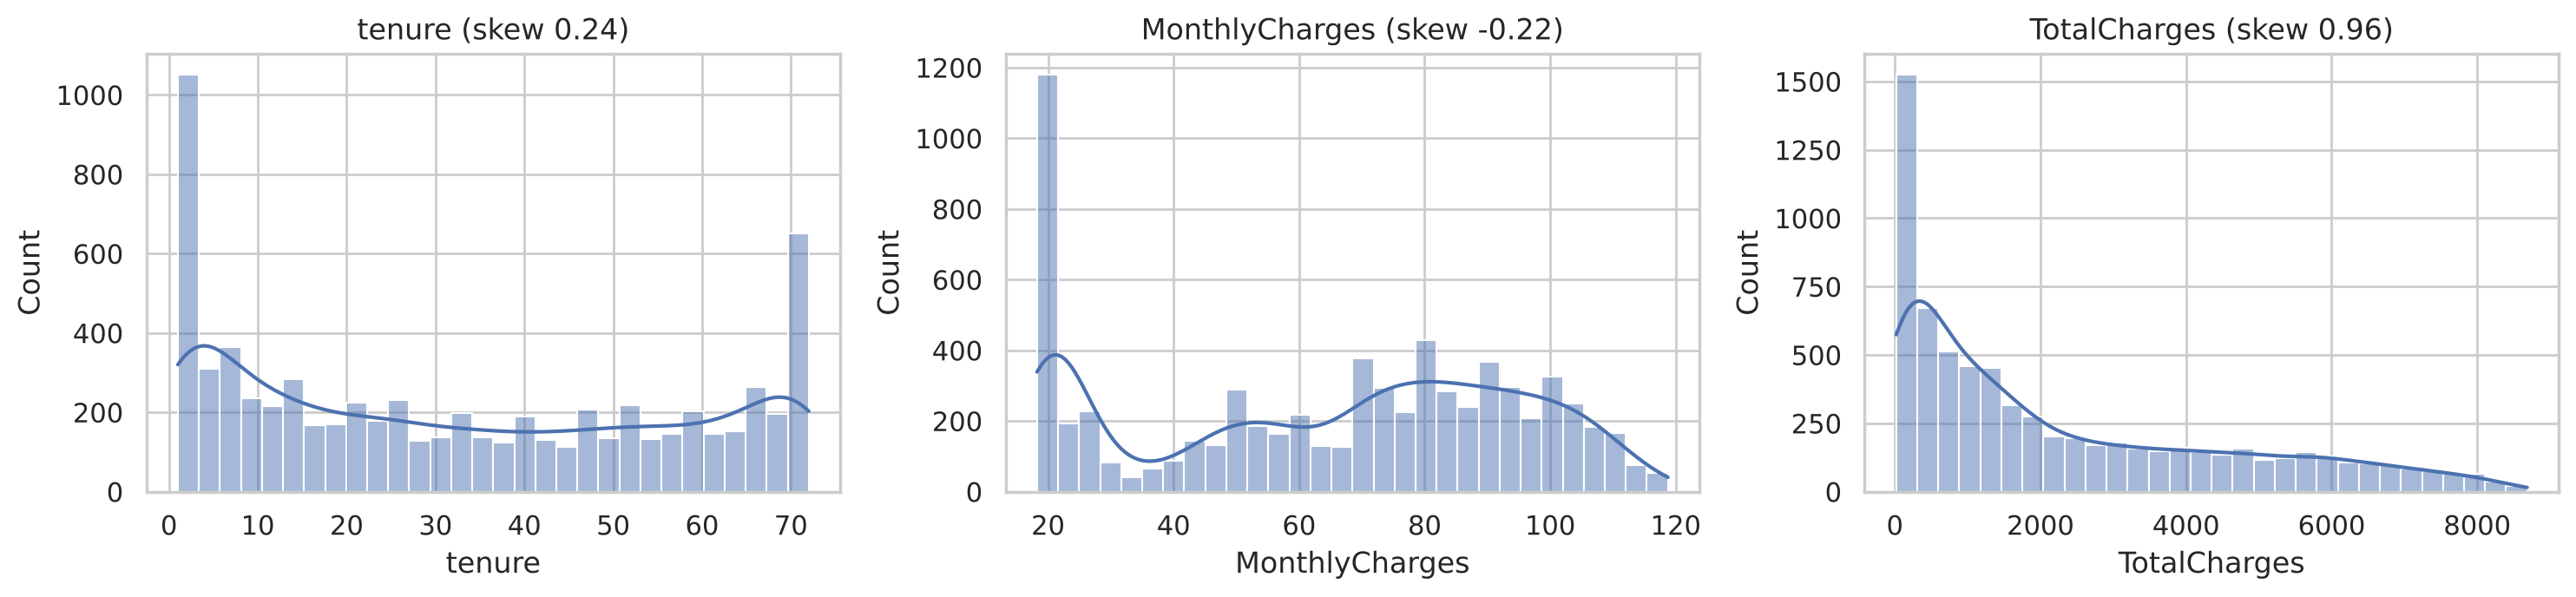

In [4]:
num_cols = ['tenure', 'MonthlyCharges', 'TotalCharges']
cat_cols = ['gender', 'SeniorCitizen', 'InternetService', 'Contract', 'PaymentMethod']
bin_cols = yes_no_cols

fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
for ax, col in zip(axes, num_cols):
    sns.histplot(df, x=col, bins=30, kde=True, ax=ax)
    ax.set_title(f"{col} (skew {df[col].skew():.2f})")
plt.tight_layout(); plt.show()

- `tenure` is U-shaped: a spike of new customers and a spike at 72 months (the dataset cap).
- `MonthlyCharges` is bimodal: a low cluster (phone-only plans) and a larger cluster around 80.
- `TotalCharges` is right-skewed, as expected from cumulative billing.

## 4. Bivariate analysis

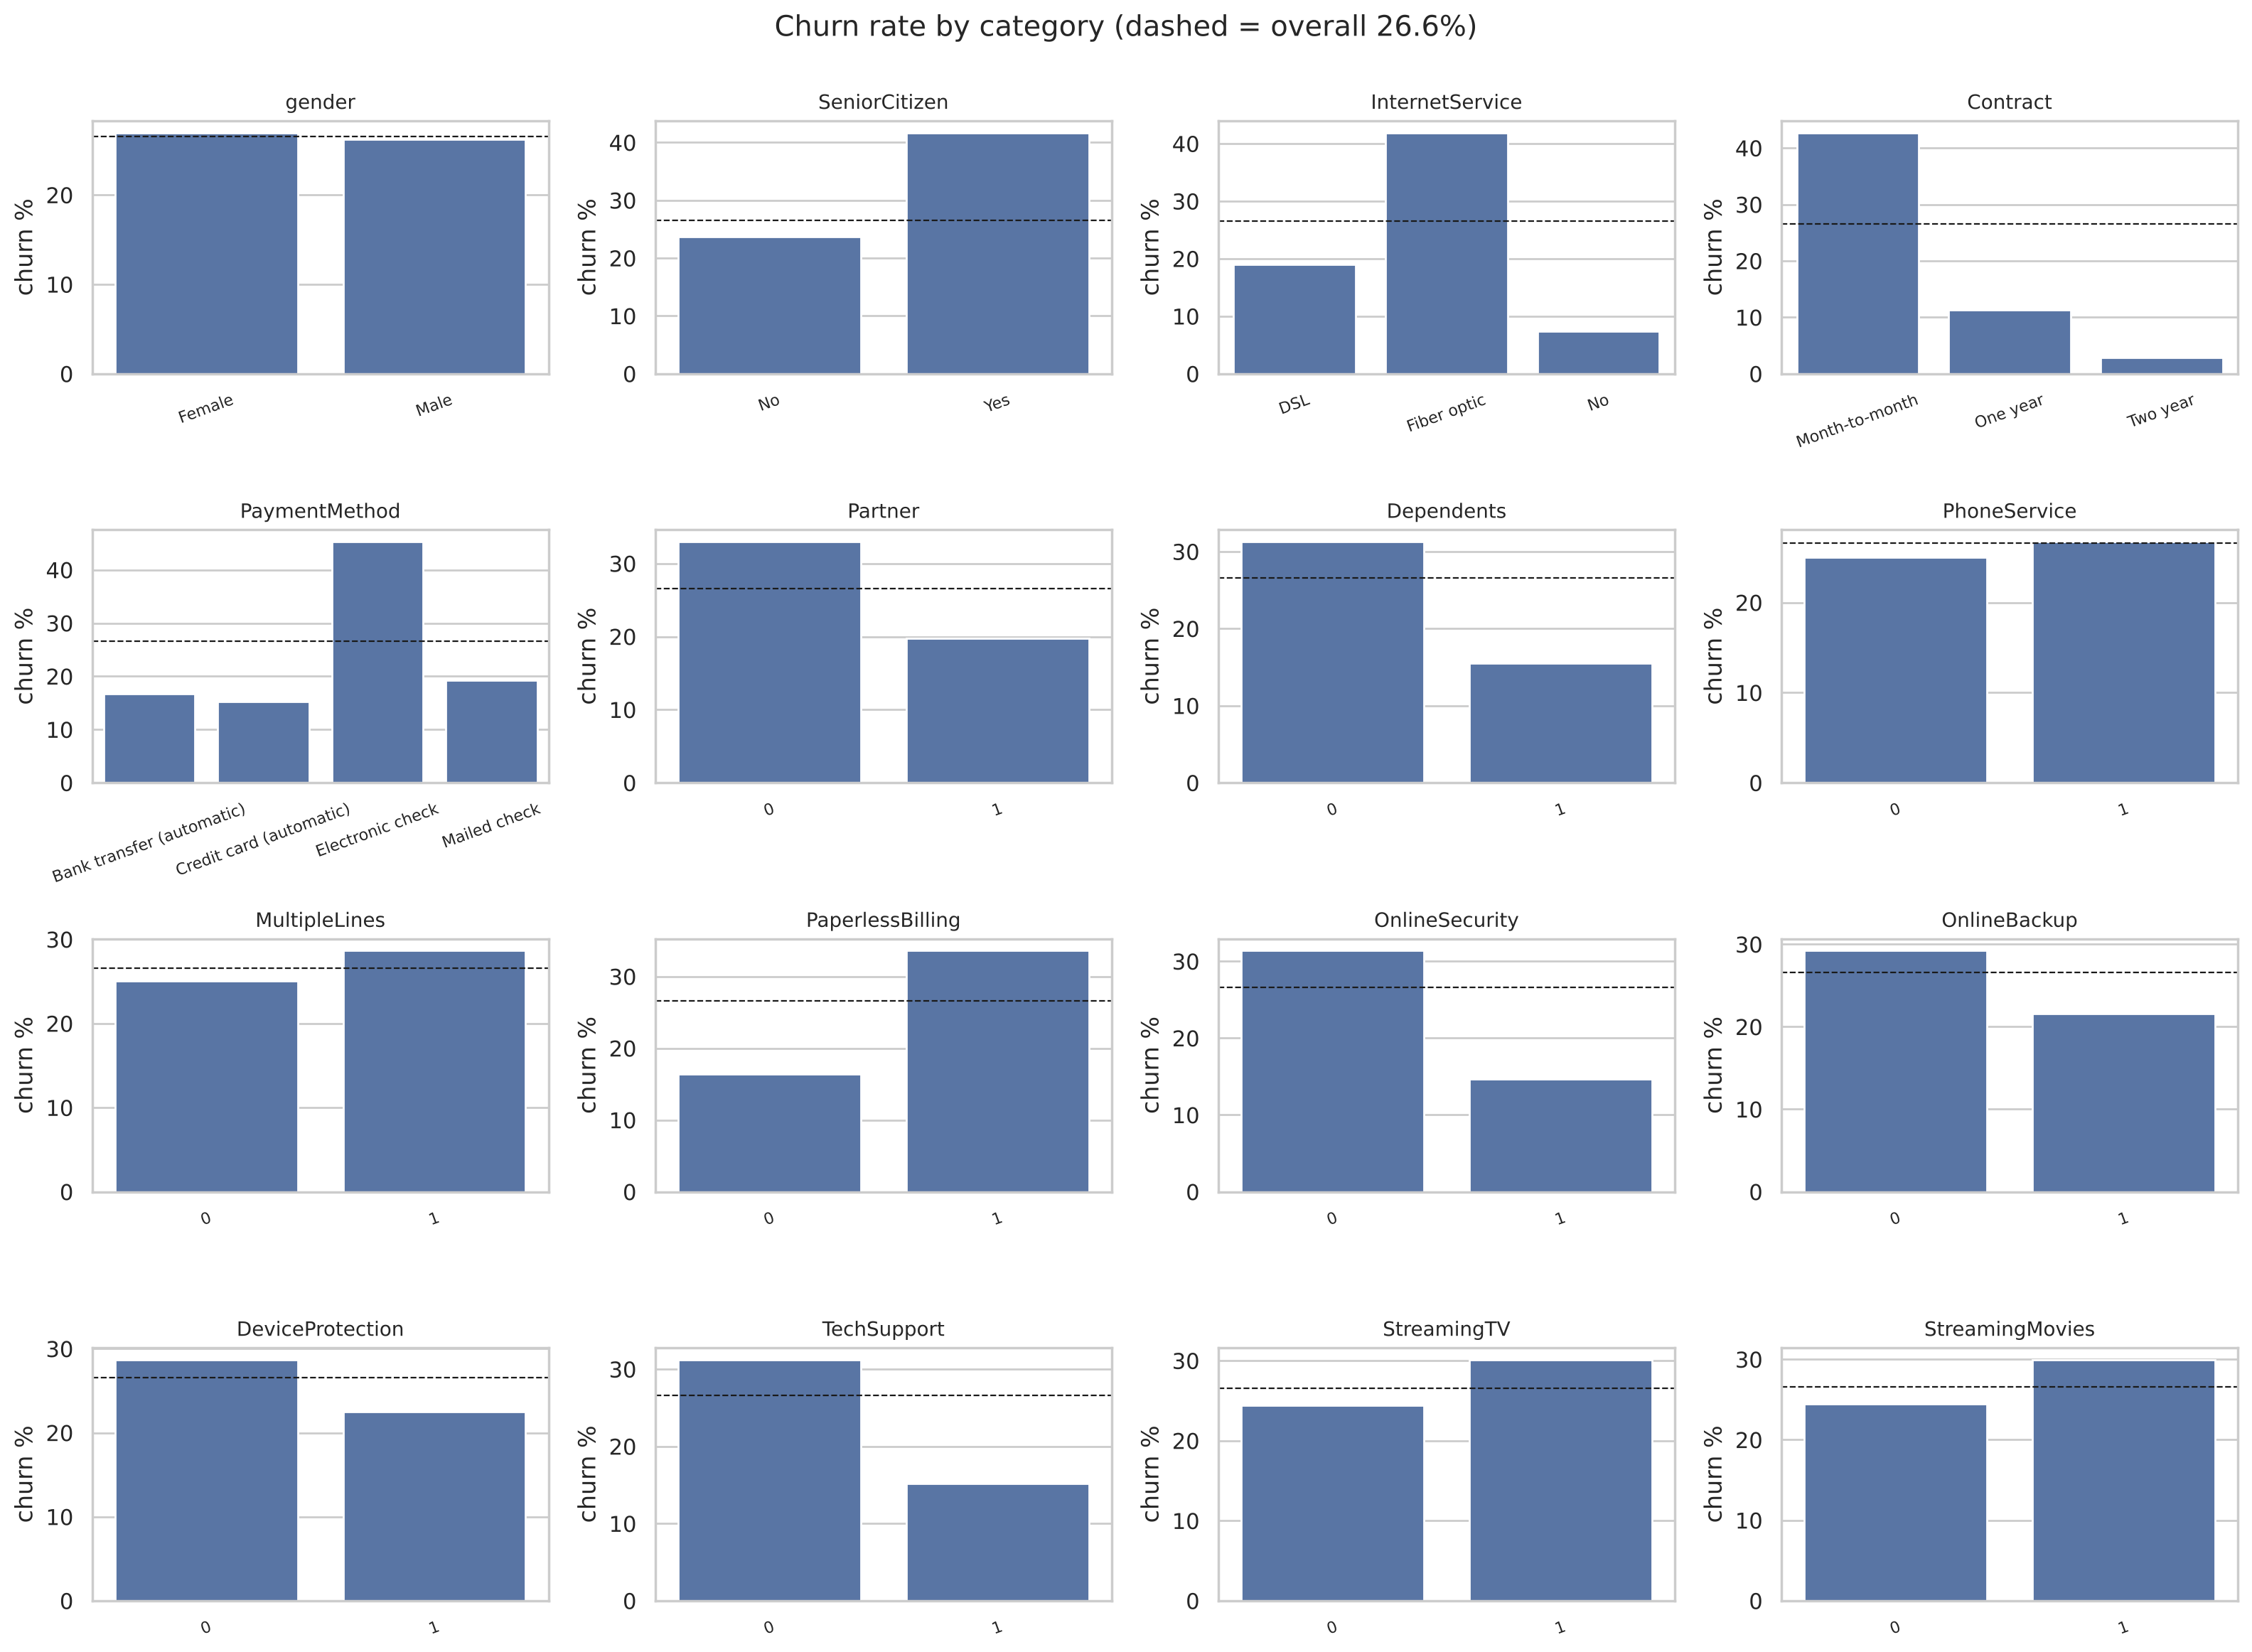

In [5]:
plot_cols = cat_cols + bin_cols
n_cols = 4
n_rows = math.ceil(len(plot_cols) / n_cols)
fig, axes = plt.subplots(n_rows, n_cols, figsize=(16, 2.9 * n_rows))
for ax, col in zip(axes.flat, plot_cols):
    rate = df.groupby(col)['Churn'].mean().mul(100)
    sns.barplot(x=rate.index.astype(str), y=rate.values, ax=ax, color='#4C72B0')
    ax.axhline(df['Churn'].mean() * 100, color='k', ls='--', lw=0.8)
    ax.set_title(col, fontsize=10); ax.set_xlabel(''); ax.set_ylabel('churn %')
    ax.tick_params(axis='x', labelrotation=20, labelsize=8)
for ax in list(axes.flat)[len(plot_cols):]:
    ax.remove()
plt.suptitle("Churn rate by category (dashed = overall 26.6%)", y=1.0)
plt.tight_layout(); plt.show()

- Gender has no effect. Phone service and multiple lines are close to neutral.
- Higher churn: month-to-month contracts, fiber optic, electronic check, paperless billing, senior citizens, no partner/dependents.
- Lower churn: online security, tech support, 1- and 2-year contracts.

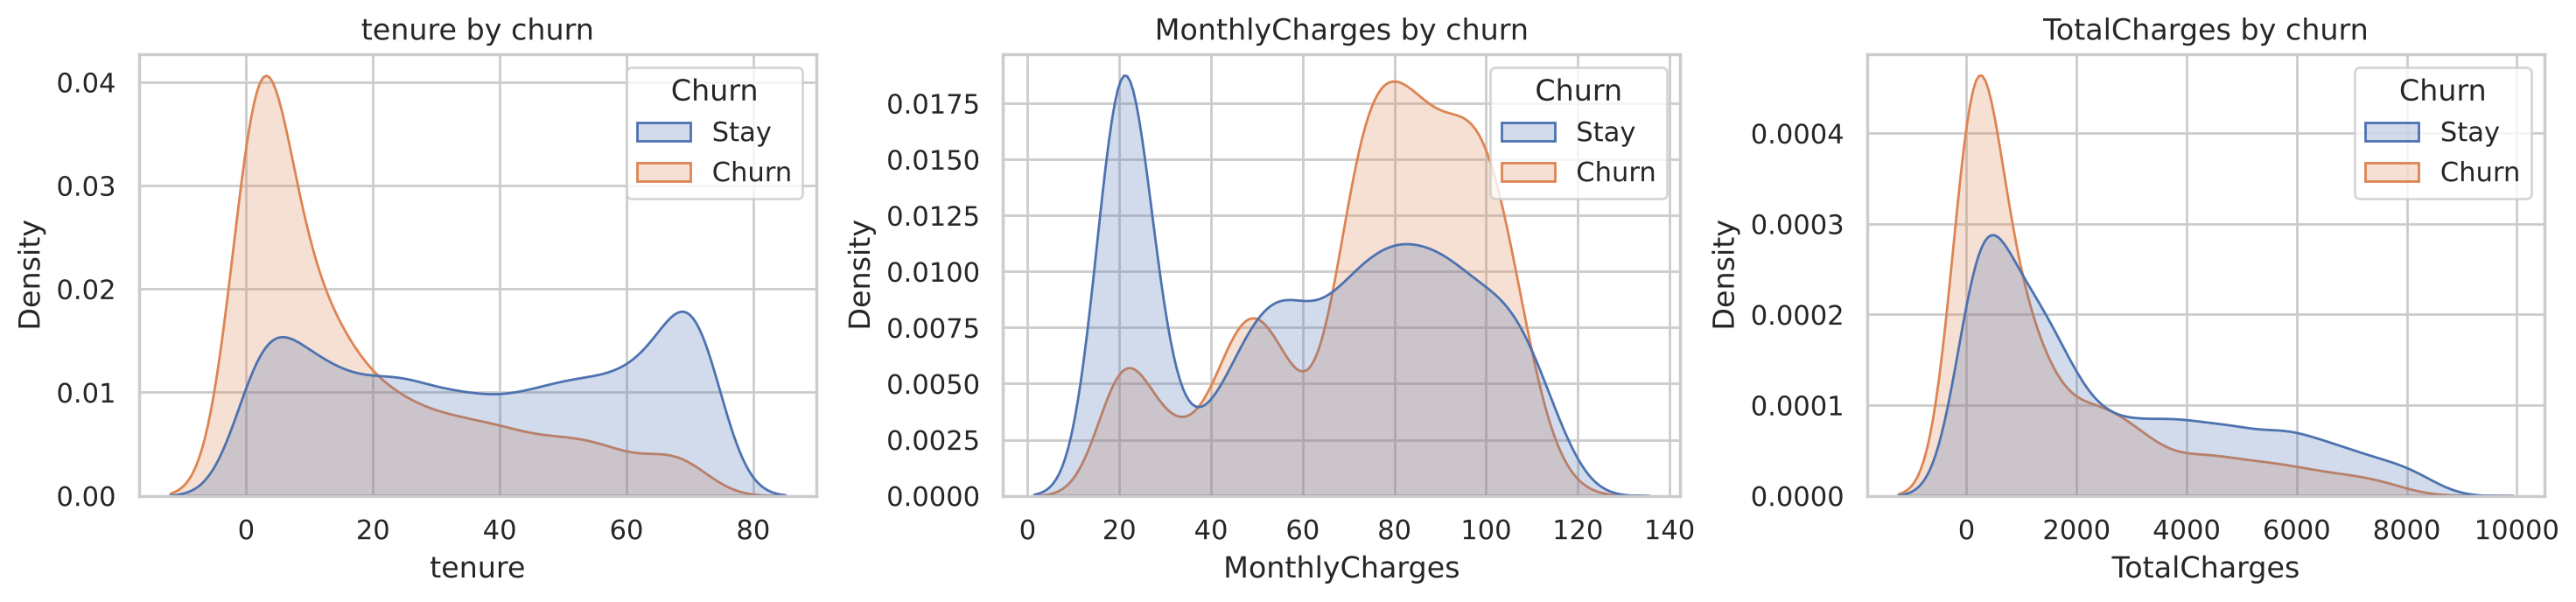

                tenure  MonthlyCharges  TotalCharges
tenure            1.00            0.28          0.89
MonthlyCharges    0.28            1.00          0.64
TotalCharges      0.89            0.64          1.00


In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
for ax, col in zip(axes, num_cols):
    sns.kdeplot(data=df, x=col, hue=df['Churn'].map({0: 'Stay', 1: 'Churn'}), common_norm=False, fill=True, ax=ax)
    ax.set_title(f"{col} by churn")
plt.tight_layout(); plt.show()

print(df[num_cols].corr(method='spearman').round(2))

- Churners are concentrated at short tenure and high monthly charges.
- `TotalCharges` is strongly tied to `tenure` (and to `MonthlyCharges`); expect collinearity for linear models.

## 5. Association with churn

Test matched to feature type:
- categorical / binary: chi-square with Cramér's V as effect size
- numeric: Mann-Whitney U with rank-biserial correlation as effect size

Chi-square is not valid for continuous columns (thousands of sparse cells), so numeric features are tested separately.

In [7]:
def cramers_v(table):
    chi2, p, _, _ = chi2_contingency(table)
    n = table.to_numpy().sum()
    return p, np.sqrt(chi2 / (n * (min(table.shape) - 1)))

rows = []
for col in cat_cols + bin_cols:
    p, v = cramers_v(pd.crosstab(df[col], df['Churn']))
    rows.append((col, 'categorical', p, v))

for col in num_cols:
    a, b = df.loc[df.Churn == 1, col], df.loc[df.Churn == 0, col]
    u, p = mannwhitneyu(a, b)
    rank_biserial = 2 * u / (len(a) * len(b)) - 1          # sign: >0 means churners have larger values
    rows.append((col, 'numeric', p, abs(rank_biserial)))

assoc = (pd.DataFrame(rows, columns=['feature', 'type', 'p_value', 'effect_size'])
           .sort_values('effect_size', ascending=False).reset_index(drop=True))
assoc['p_value'] = assoc['p_value'].map(lambda p: f"{p:.2e}")
assoc.round(3)

,feature,type,p_value,effect_size
0,tenure,numeric,6.04e-211,0.483
1,Contract,categorical,7.33e-257,0.410
2,InternetService,categorical,5.83e-159,0.322
3,TotalCharges,numeric,2.00e-84,0.303
4,PaymentMethod,categorical,1.43e-139,0.303
5,MonthlyCharges,numeric,8.47e-54,0.241
6,PaperlessBilling,categorical,8.24e-58,0.191
7,OnlineSecurity,categorical,1.37e-46,0.171
8,TechSupport,categorical,3.23e-43,0.164
9,Dependents,categorical,2.02e-42,0.163


- Strongest: `tenure`, `Contract`, `InternetService`, `TotalCharges`, `PaymentMethod`, then `MonthlyCharges`.
- `gender` and `PhoneService` are not associated with churn (p > 0.05) and carry negligible effect.
- With n ≈ 7,000 nearly everything is significant; effect size is what separates the features.
- Effect sizes are comparable only within a test family (Cramér's V vs rank-biserial are on different scales).

## 6. Feature engineering

Three count features summarising service uptake, plus `avg_monthly_spend` (`TotalCharges / tenure`) to capture price drift relative to current `MonthlyCharges`.
Kept only if they improve CV; see section 8.

In [8]:
df['protection_count'] = df[['OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport']].sum(axis=1)
df['streaming_count'] = df[['StreamingTV', 'StreamingMovies']].sum(axis=1)
df['service_count'] = df['protection_count'] + df['streaming_count']
df['avg_monthly_spend'] = df['TotalCharges'] / df['tenure']

engineered = ['protection_count', 'streaming_count', 'service_count', 'avg_monthly_spend']
print(df[engineered].describe().round(2).T[['mean', 'std', 'min', 'max']])

                    mean    std    min    max
protection_count    1.27   1.29   0.00    4.0
streaming_count     0.77   0.85   0.00    2.0
service_count       2.04   1.85   0.00    6.0
avg_monthly_spend  64.80  30.19  13.78  121.4


## 7. Split and baseline

In [9]:
X, y = df.drop(columns='Churn'), df['Churn']
x_train, x_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)
print("train:", x_train.shape, "| test:", x_test.shape,
      "| churn rate train/test:", round(y_train.mean(), 3), round(y_test.mean(), 3))

dummy = DummyClassifier(strategy='prior').fit(x_train, y_train)
p0 = dummy.predict_proba(x_test)[:, 1]
print("Baseline accuracy (predict all 'stay'):", round(dummy.score(x_test, y_test), 3),
      "| ROC-AUC:", round(roc_auc_score(y_test, p0), 3), "| PR-AUC:", round(average_precision_score(y_test, p0), 3))

train: (5625, 23) | test: (1407, 23) | churn rate train/test: 0.266 0.266


Baseline accuracy (predict all 'stay'): 0.734 | ROC-AUC: 0.5 | PR-AUC: 0.266


In [10]:
NUM = ['tenure', 'MonthlyCharges', 'TotalCharges', 'avg_monthly_spend']
base_features = [c for c in X.columns if c not in engineered]
eng_features = base_features + engineered
feature_sets = {'base': base_features, 'base + engineered': eng_features}

def make_pipe(features, model):
    cat = [c for c in features if not pd.api.types.is_numeric_dtype(X[c])]
    num = [c for c in NUM if c in features]
    pre = ColumnTransformer(
        [('num', StandardScaler(), num),
         ('cat', OneHotEncoder(drop='first', handle_unknown='ignore'), cat)],
        remainder='passthrough')
    return Pipeline([('prep', pre), ('model', model)])

# No class_weight anywhere: the threshold is tuned on cost, and weighting would distort the probabilities used for it.
models = {
    'Logistic Regression':    LogisticRegression(max_iter=2000),
    'Decision Tree':          DecisionTreeClassifier(max_depth=5, min_samples_leaf=30, random_state=RANDOM_STATE),
    'Random Forest':          RandomForestClassifier(n_estimators=300, min_samples_leaf=5, n_jobs=-1, random_state=RANDOM_STATE),
    'Extra Trees':            ExtraTreesClassifier(n_estimators=300, min_samples_leaf=5, n_jobs=-1, random_state=RANDOM_STATE),
    'Gradient Boosting':      GradientBoostingClassifier(random_state=RANDOM_STATE),
    'Hist Gradient Boosting': HistGradientBoostingClassifier(random_state=RANDOM_STATE),
    'SVM (RBF)':              SVC(probability=True, random_state=RANDOM_STATE),
    'KNN':                    KNeighborsClassifier(n_neighbors=25, weights='distance', n_jobs=-1),
}

## 8. Model comparison (5-fold stratified CV, training split only)

Metrics: ROC-AUC and PR-AUC (threshold-free). The positive class is a minority, so PR-AUC is the more informative of the two.

In [11]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

rows = []
for mname, model in models.items():
    for fname, feats in feature_sets.items():
        s = cross_validate(make_pipe(feats, clone(model)), x_train[feats], y_train, cv=cv,
                           scoring={'auc': 'roc_auc', 'ap': 'average_precision'}, n_jobs=-1)
        rows.append((mname, fname, s['test_auc'].mean(), s['test_auc'].std(), s['test_ap'].mean(), s['test_ap'].std()))

cv_table = pd.DataFrame(rows, columns=['model', 'features', 'auc', 'auc_sd', 'pr_auc', 'pr_auc_sd'])
cv_table.sort_values('pr_auc', ascending=False).round(4).reset_index(drop=True)

,model,features,auc,auc_sd,pr_auc,pr_auc_sd
0,Gradient Boosting,base,0.8478,0.0037,0.6642,0.0090
1,Random Forest,base,0.8463,0.0058,0.6639,0.0169
2,Gradient Boosting,base + engineered,0.8480,0.0035,0.6636,0.0089
3,Random Forest,base + engineered,0.8456,0.0049,0.6625,0.0184
4,Logistic Regression,base + engineered,0.8459,0.0053,0.6608,0.0118
5,Logistic Regression,base,0.8460,0.0053,0.6598,0.0115
6,Extra Trees,base,0.8439,0.0070,0.6522,0.0183
7,Hist Gradient Boosting,base,0.8392,0.0038,0.6498,0.0089
8,Extra Trees,base + engineered,0.8435,0.0069,0.6494,0.0207
9,SVM (RBF),base + engineered,0.8148,0.0118,0.6473,0.0154


In [12]:
pivot = cv_table.pivot(index='model', columns='features', values='pr_auc')
pivot['delta (eng - base)'] = pivot['base + engineered'] - pivot['base']
pivot.sort_values('base', ascending=False).round(4)

features,base,base + engineered,delta (eng - base)
model,,,
Gradient Boosting,0.6642,0.6636,-0.0006
Random Forest,0.6639,0.6625,-0.0014
Logistic Regression,0.6598,0.6608,0.0009
Extra Trees,0.6522,0.6494,-0.0027
Hist Gradient Boosting,0.6498,0.6411,-0.0087
SVM (RBF),0.6388,0.6473,0.0084
Decision Tree,0.6108,0.6148,0.0041
KNN,0.6019,0.6013,-0.0006


- Gradient Boosting, Random Forest and Logistic Regression lead (PR-AUC 0.66, ROC-AUC 0.846-0.848); gaps between them are within one CV standard deviation.
- Extra Trees and Hist Gradient Boosting follow; SVM, KNN and the depth-limited tree trail.
- Engineered features give no consistent lift: deltas are within ±0.003 for most models. The largest (SVM, +0.008) is below its fold SD (0.015). Base features are used.

## 9. Hyperparameter tuning

Randomised search on the training split (5-fold CV, PR-AUC) for the two leading model families.
Search is run on the base feature set unless the engineered set was clearly better above.

In [13]:
FEATS = base_features

search_spaces = {
    'Logistic Regression': (
        LogisticRegression(max_iter=3000),
        {'model__C': np.logspace(-3, 2, 30), 'model__penalty': ['l2']}),
    'Gradient Boosting': (
        GradientBoostingClassifier(random_state=RANDOM_STATE),
        {'model__n_estimators': [100, 200, 300, 500],
         'model__learning_rate': [0.01, 0.02, 0.05, 0.1],
         'model__max_depth': [2, 3, 4],
         'model__min_samples_leaf': [10, 20, 40, 80],
         'model__subsample': [0.6, 0.8, 1.0],
         'model__max_features': [None, 'sqrt', 0.5]}),
}

tuned = {}
for name, (est, space) in search_spaces.items():
    rs = RandomizedSearchCV(make_pipe(FEATS, est), space, n_iter=30, scoring='average_precision',
                            cv=cv, random_state=RANDOM_STATE, n_jobs=-1, refit=True)
    rs.fit(x_train[FEATS], y_train)
    tuned[name] = rs.best_estimator_
    default = cv_table.query("model == @name and features == 'base'")['pr_auc'].iloc[0]
    print(f"{name:20s} CV PR-AUC default={default:.4f} -> tuned={rs.best_score_:.4f}")
    print("   ", {k.replace('model__', ''): v for k, v in rs.best_params_.items()})

Logistic Regression  CV PR-AUC default=0.6598 -> tuned=0.6601
    {'penalty': 'l2', 'C': np.float64(0.38566204211634725)}


Gradient Boosting    CV PR-AUC default=0.6642 -> tuned=0.6716
    {'subsample': 0.8, 'n_estimators': 300, 'min_samples_leaf': 20, 'max_features': 'sqrt', 'max_depth': 2, 'learning_rate': 0.05}


Logistic Regression does not move (0.6598 → 0.6601). Gradient Boosting gains +0.007 PR-AUC with shallow trees (depth 2), subsampling and a low learning rate. The tuned models are used from here on. Note that CV scores of the tuned models are slightly optimistic, since the search used the same folds.

## 10. Threshold selection by business cost

Per customer flagged: pay `OFFER_COST`. Per churner missed: lose `LOSS_COST`. Per churner flagged: the offer succeeds with probability `SAVE_RATE`, otherwise `LOSS_COST` is still lost.

**The three costs are assumptions, not measured values.** Results below are indicative of the method; absolute figures depend on these inputs.

Break-even rule: flag when `p × SAVE_RATE × LOSS_COST > OFFER_COST`, i.e. p > 0.31 with the values below.
Thresholds are chosen on out-of-fold training predictions only; the test set is used once afterwards.

In [14]:
OFFER_COST, LOSS_COST, SAVE_RATE = 50, 400, 0.40

def total_cost(y_true, prob, t, offer=OFFER_COST, loss=LOSS_COST, save=SAVE_RATE):
    y_true = np.asarray(y_true); flag = prob >= t
    missed = (~flag) & (y_true == 1)
    caught = flag & (y_true == 1)
    return flag.sum() * offer + missed.sum() * loss + caught.sum() * loss * (1 - save)

thresholds = np.arange(0.05, 0.96, 0.01)

def best_threshold(y_true, prob, **kw):
    costs = np.array([total_cost(y_true, prob, t, **kw) for t in thresholds])
    return thresholds[costs.argmin()], costs.min()

oof = {}
for name, est in tuned.items():
    oof[name] = cross_val_predict(clone(est), x_train[FEATS], y_train, cv=cv, method='predict_proba', n_jobs=-1)[:, 1]
oof['Logistic Regression (default)'] = cross_val_predict(
    make_pipe(FEATS, LogisticRegression(max_iter=2000)), x_train[FEATS], y_train, cv=cv, method='predict_proba', n_jobs=-1)[:, 1]

cost_no_action_train = y_train.sum() * LOSS_COST
rows = []
for name, p in oof.items():
    t, c = best_threshold(y_train, p)
    rows.append((name, t, c, 1 - c / cost_no_action_train, roc_auc_score(y_train, p), average_precision_score(y_train, p)))
oof_table = pd.DataFrame(rows, columns=['model', 'threshold', 'oof_cost', 'saving_vs_no_action', 'oof_auc', 'oof_pr_auc'])
oof_table.round(4)

,model,threshold,oof_cost,saving_vs_no_action,oof_auc,oof_pr_auc
0,Logistic Regression,0.31,519840.0,0.1307,0.8454,0.6573
1,Gradient Boosting,0.33,518730.0,0.1326,0.8512,0.6686
2,Logistic Regression (default),0.32,519810.0,0.1308,0.8456,0.6573


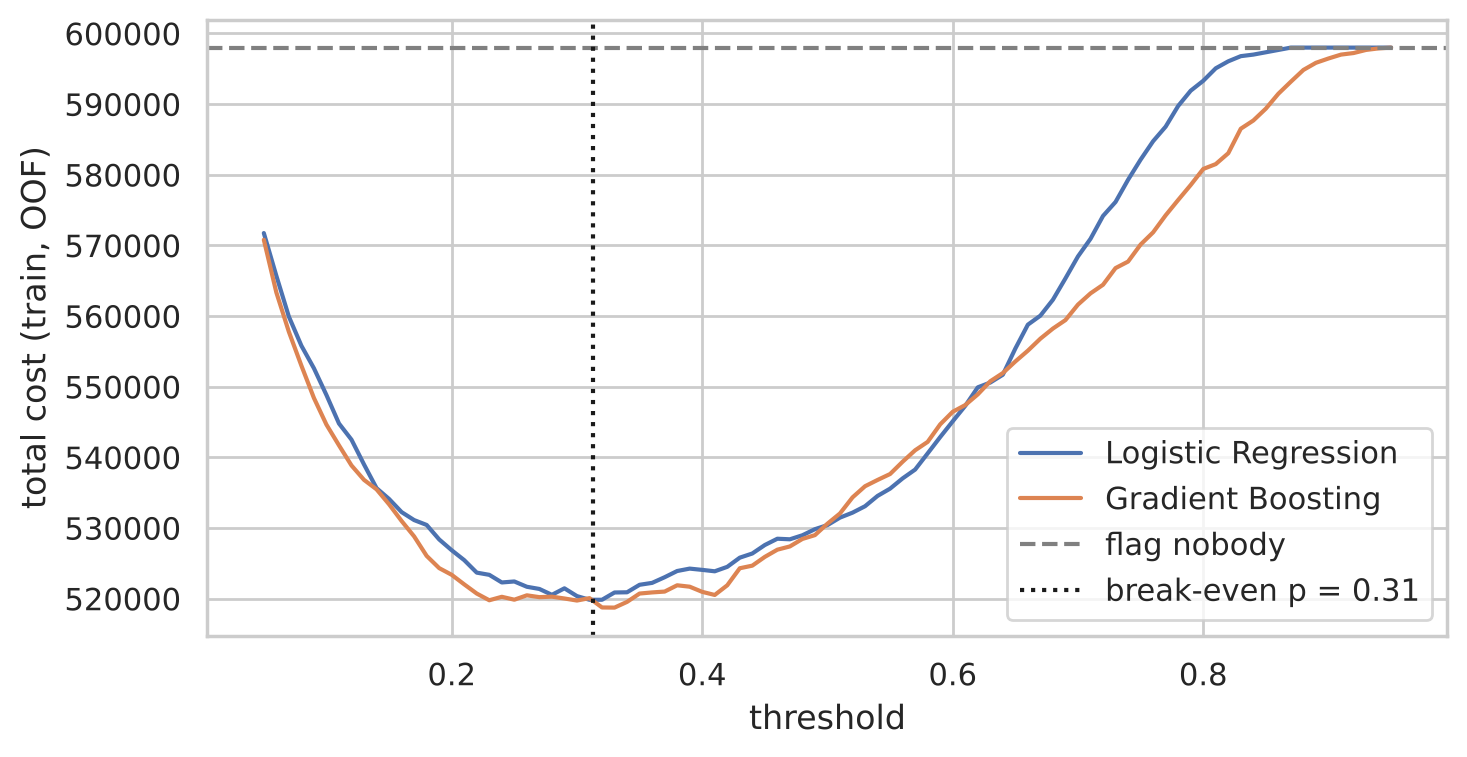

In [15]:
fig, ax = plt.subplots(figsize=(8, 4))
for name in tuned:
    ax.plot(thresholds, [total_cost(y_train, oof[name], t) for t in thresholds], label=name)
ax.axhline(cost_no_action_train, color='grey', ls='--', label='flag nobody')
ax.axvline(OFFER_COST / (SAVE_RATE * LOSS_COST), color='k', ls=':', label='break-even p = 0.31')
ax.set_xlabel('threshold'); ax.set_ylabel('total cost (train, OOF)'); ax.legend(); plt.show()

Optimal thresholds (0.31-0.33) sit at the break-even probability of 0.31, and the cost curve is flat around the optimum. OOF saving vs. flagging nobody is ~13% for both models.

## 11. Final test evaluation

Model selection is made on OOF cost. Where the top models are within noise, the simpler/interpretable one is preferred; the two are both reported on test.

In [16]:
best_name = oof_table.loc[oof_table['model'].isin(tuned)].sort_values('oof_cost').iloc[0]['model']
print("Selected on OOF cost:", best_name)

results, test_probs = [], {}
for name, est in tuned.items():
    m = clone(est).fit(x_train[FEATS], y_train)
    p = m.predict_proba(x_test[FEATS])[:, 1]
    t = oof_table.set_index('model').loc[name, 'threshold']
    test_probs[name] = (m, p, t)
    results.append((name, t, roc_auc_score(y_test, p), average_precision_score(y_test, p),
                    brier_score_loss(y_test, p),
                    total_cost(y_test, p, t), total_cost(y_test, p, 0.5)))

test_table = pd.DataFrame(results, columns=['model', 'threshold', 'roc_auc', 'pr_auc', 'brier', 'cost@opt', 'cost@0.5'])
cost_none = y_test.sum() * LOSS_COST
cost_all = total_cost(y_test, np.ones(len(y_test)), 0.5)
test_table['saving_vs_no_action'] = 1 - test_table['cost@opt'] / cost_none
print(f"Reference test costs: flag nobody = {cost_none:.0f} | flag everybody = {cost_all:.0f}")
test_table.round(4)

Selected on OOF cost: Gradient Boosting


Reference test costs: flag nobody = 149600 | flag everybody = 160110


,model,threshold,roc_auc,pr_auc,brier,cost@opt,cost@0.5,saving_vs_no_action
0,Logistic Regression,0.31,0.8363,0.6238,0.1398,131600.0,131980.0,0.1203
1,Gradient Boosting,0.33,0.8414,0.6581,0.1373,130680.0,133120.0,0.1265


Gradient Boosting | threshold 0.33
              precision    recall  f1-score   support

        Stay       0.89      0.78      0.83      1033
       Churn       0.55      0.74      0.63       374

    accuracy                           0.77      1407
   macro avg       0.72      0.76      0.73      1407
weighted avg       0.80      0.77      0.78      1407



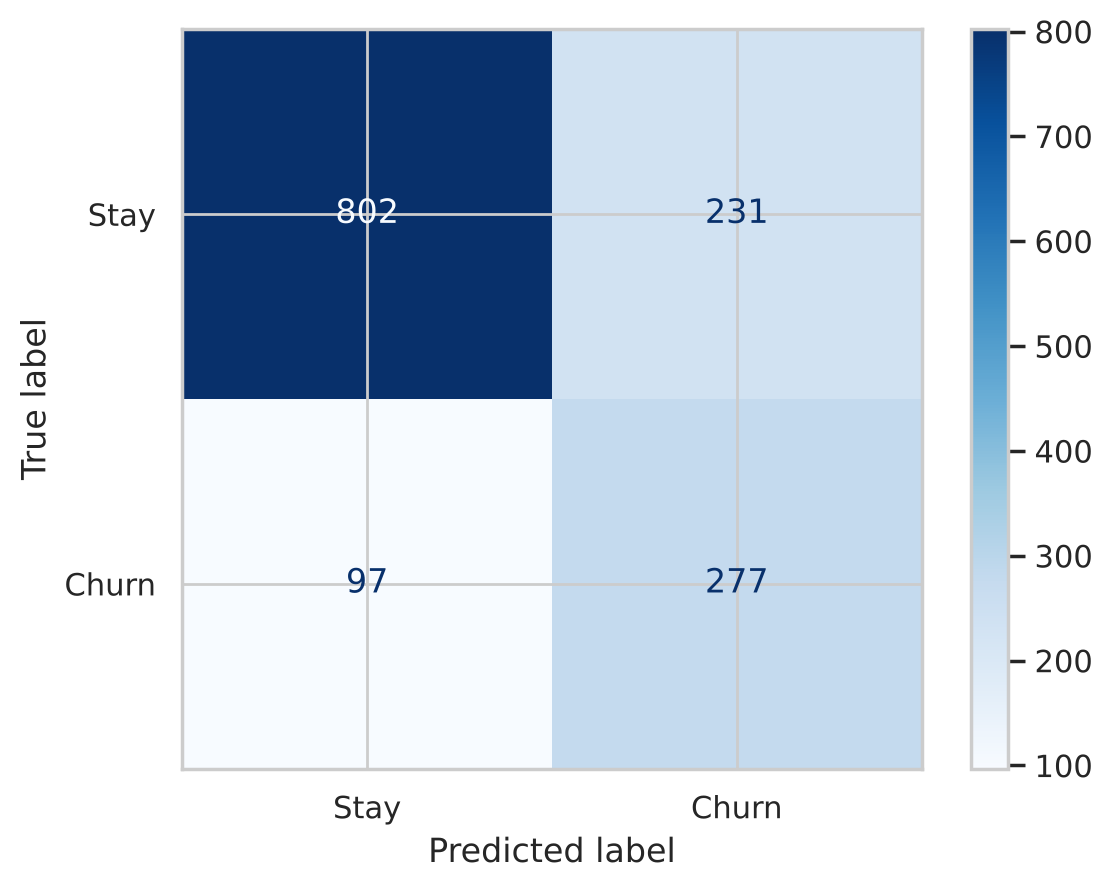

In [17]:
m, p, t = test_probs[best_name]
pred = (p >= t).astype(int)
print(f"{best_name} | threshold {t:.2f}")
print(classification_report(y_test, pred, target_names=['Stay', 'Churn']))
ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=['Stay', 'Churn'], cmap='Blues')
plt.show()

In [18]:
# Bootstrap CIs on the test set (2,000 resamples) for the selected model
rng = np.random.default_rng(RANDOM_STATE)
yt, n = y_test.to_numpy(), len(y_test)
boot = {'roc_auc': [], 'pr_auc': [], 'saving': []}
for _ in range(2000):
    idx = rng.integers(0, n, n)
    if yt[idx].sum() == 0: continue
    boot['roc_auc'].append(roc_auc_score(yt[idx], p[idx]))
    boot['pr_auc'].append(average_precision_score(yt[idx], p[idx]))
    boot['saving'].append(1 - total_cost(yt[idx], p[idx], t) / (yt[idx].sum() * LOSS_COST))
for k, v in boot.items():
    lo, hi = np.percentile(v, [2.5, 97.5])
    print(f"{k:8s} {np.mean(v):.3f}  95% CI [{lo:.3f}, {hi:.3f}]")

# Paired bootstrap on the same resamples: Gradient Boosting minus Logistic Regression
p_lr = test_probs['Logistic Regression'][1]
d_auc, d_ap = [], []
for _ in range(2000):
    idx = rng.integers(0, n, n)
    d_auc.append(roc_auc_score(yt[idx], p[idx]) - roc_auc_score(yt[idx], p_lr[idx]))
    d_ap.append(average_precision_score(yt[idx], p[idx]) - average_precision_score(yt[idx], p_lr[idx]))
for k, v in [('GB - LR roc_auc', d_auc), ('GB - LR pr_auc', d_ap)]:
    lo, hi = np.percentile(v, [2.5, 97.5])
    print(f"{k:16s} {np.mean(v):+.4f}  95% CI [{lo:+.4f}, {hi:+.4f}]")

roc_auc  0.841  95% CI [0.820, 0.862]
pr_auc   0.659  95% CI [0.608, 0.707]
saving   0.126  95% CI [0.108, 0.143]


GB - LR roc_auc  +0.0051  95% CI [-0.0007, +0.0113]
GB - LR pr_auc   +0.0333  95% CI [+0.0126, +0.0551]


Paired bootstrap, Gradient Boosting minus Logistic Regression: ROC-AUC difference is small and its interval touches zero; the PR-AUC difference (+0.03) is positive with an interval above zero. Gradient Boosting has a real but modest edge in precision on the top-ranked customers. The cost difference between the two on test is ~900 (0.7%), so Logistic Regression remains a reasonable choice if interpretability is required.

## 12. Calibration

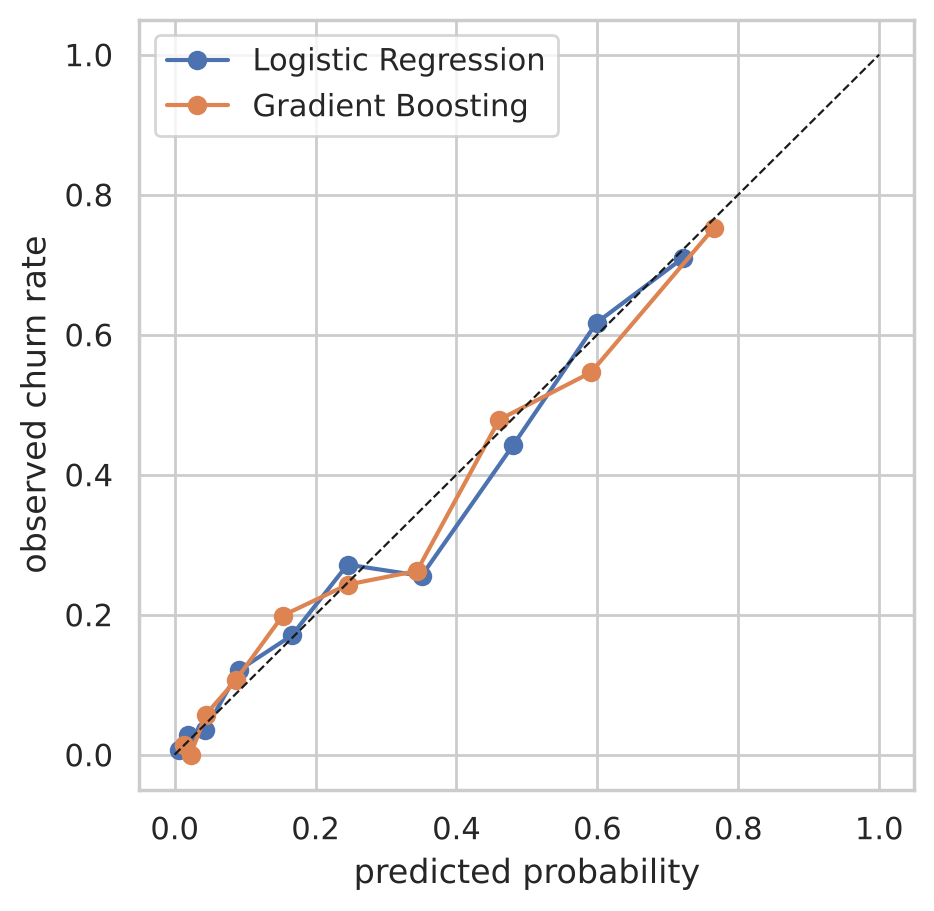

Logistic Regression  mean |pred - obs| over deciles: 0.024 | Brier 0.1398
Gradient Boosting    mean |pred - obs| over deciles: 0.026 | Brier 0.1373


In [19]:
fig, ax = plt.subplots(figsize=(5, 5))
for name, (_, pp, _) in test_probs.items():
    frac, mean_p = calibration_curve(y_test, pp, n_bins=10, strategy='quantile')
    ax.plot(mean_p, frac, marker='o', label=name)
ax.plot([0, 1], [0, 1], 'k--', lw=0.8)
ax.set_xlabel('predicted probability'); ax.set_ylabel('observed churn rate'); ax.legend(); plt.show()

for name, (_, pp, _) in test_probs.items():
    frac, mean_p = calibration_curve(y_test, pp, n_bins=10, strategy='quantile')
    print(f"{name:20s} mean |pred - obs| over deciles: {np.abs(frac - mean_p).mean():.3f} | Brier {brier_score_loss(y_test, pp):.4f}")

Both models are well calibrated without class weighting (mean decile gap 0.024 for LR, 0.026 for GB; Brier 0.140 / 0.137), which is what makes the probability-based threshold and the break-even rule usable.

## 13. What drives churn

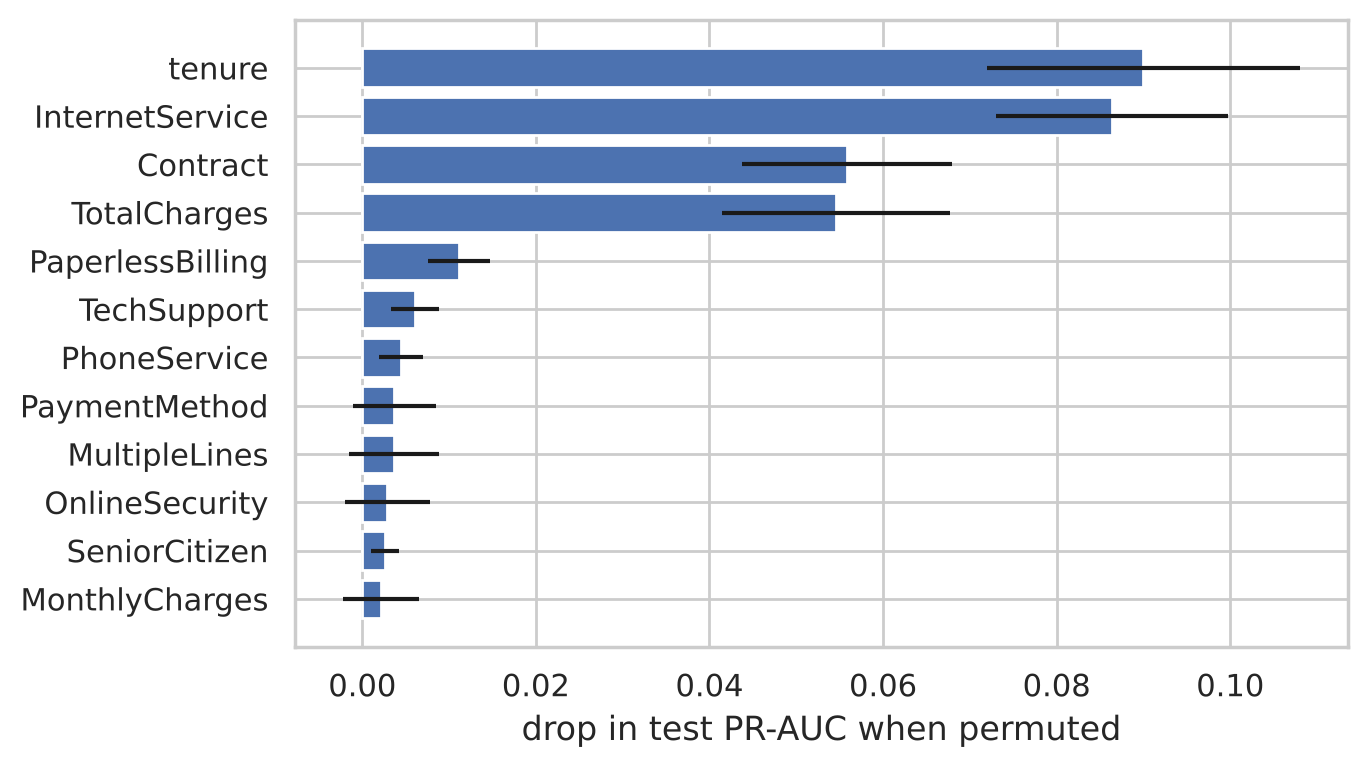

,feature,drop_in_pr_auc,sd
4,tenure,0.0900,0.0181
7,InternetService,0.0864,0.0134
14,Contract,0.0559,0.0121
18,TotalCharges,0.0546,0.0131
15,PaperlessBilling,0.0111,0.0036
11,TechSupport,0.0061,0.0027
5,PhoneService,0.0045,0.0025
16,PaymentMethod,0.0037,0.0048
6,MultipleLines,0.0036,0.0052
8,OnlineSecurity,0.0029,0.0049


In [20]:
m_best = test_probs[best_name][0]
perm = permutation_importance(m_best, x_test[FEATS], y_test, scoring='average_precision',
                              n_repeats=20, random_state=RANDOM_STATE, n_jobs=-1)
imp = (pd.DataFrame({'feature': FEATS, 'drop_in_pr_auc': perm.importances_mean, 'sd': perm.importances_std})
         .sort_values('drop_in_pr_auc', ascending=False).head(12))

fig, ax = plt.subplots(figsize=(7, 4))
ax.barh(imp['feature'][::-1], imp['drop_in_pr_auc'][::-1], xerr=imp['sd'][::-1], color='#4C72B0')
ax.set_xlabel('drop in test PR-AUC when permuted'); plt.tight_layout(); plt.show()
imp.round(4)

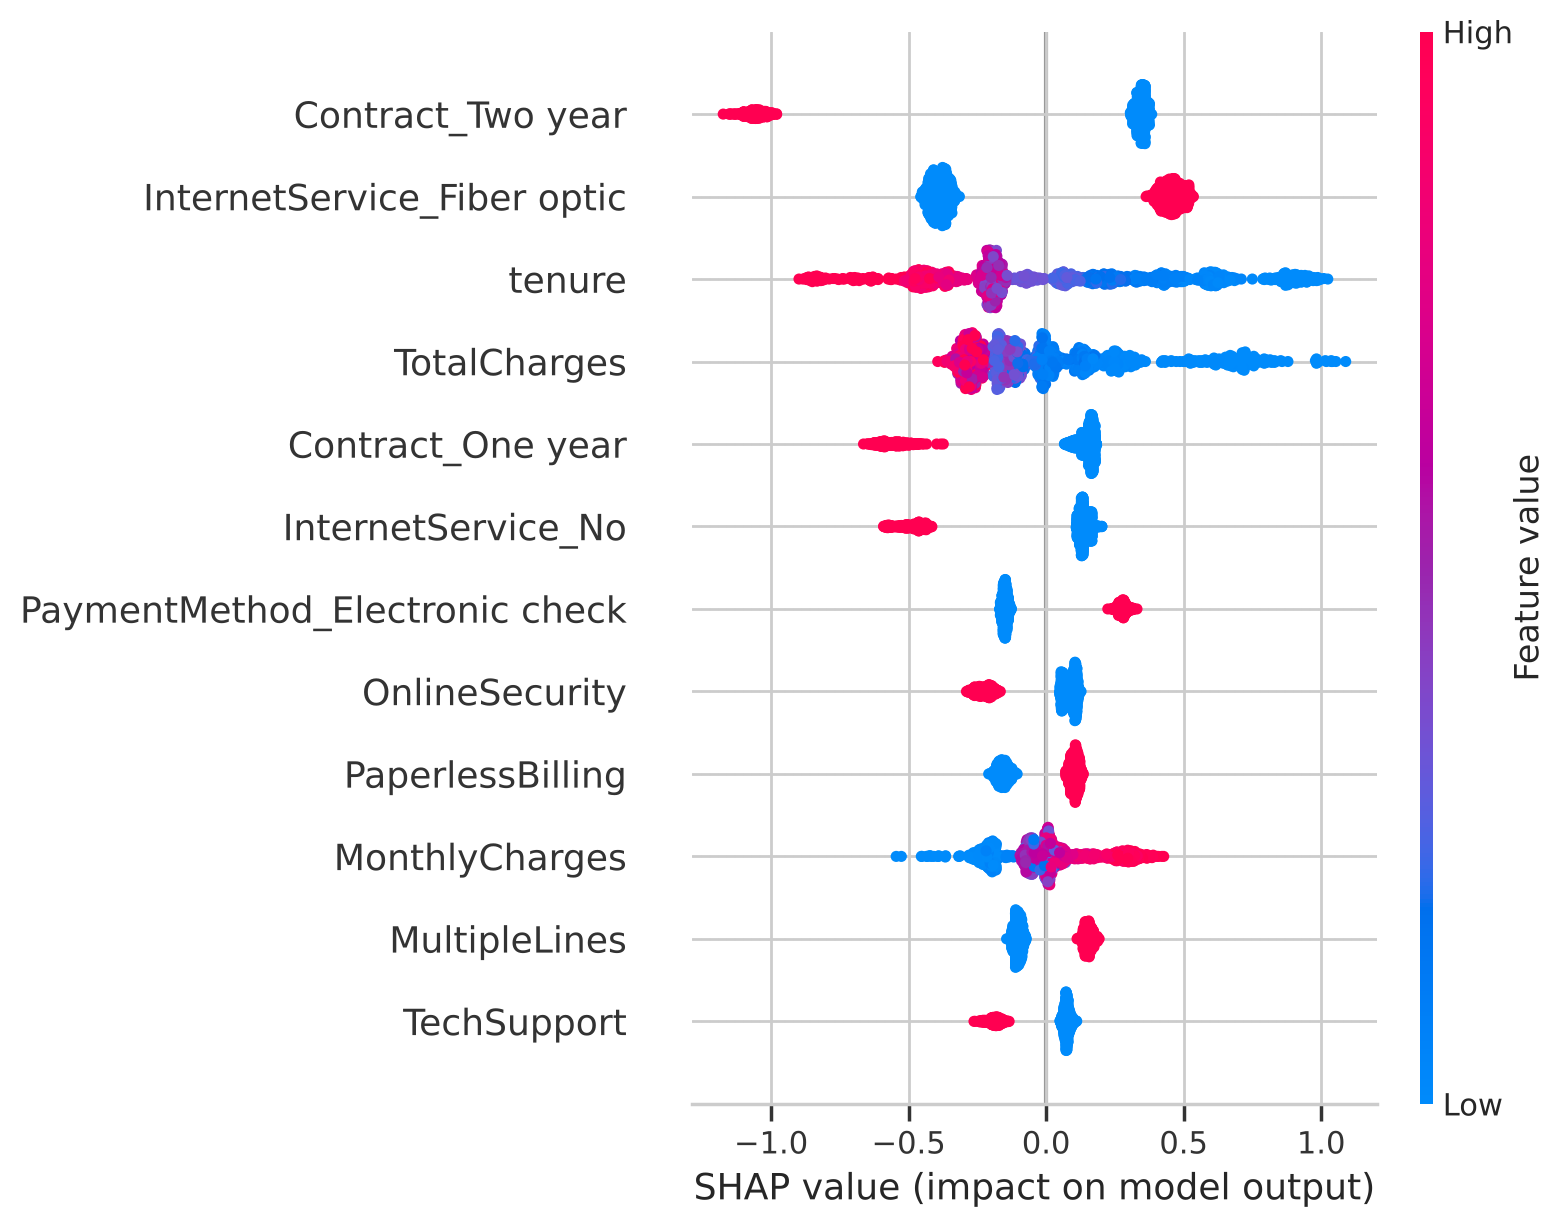

In [21]:
import shap
gb = tuned['Gradient Boosting']
Xt = gb.named_steps['prep'].transform(x_train[FEATS])
Xs = gb.named_steps['prep'].transform(x_test[FEATS])
names = [n.split('__', 1)[1] for n in gb.named_steps['prep'].get_feature_names_out()]
Xs = Xs.toarray() if hasattr(Xs, 'toarray') else Xs

explainer = shap.TreeExplainer(gb.named_steps['model'])
sv = explainer.shap_values(Xs)
shap.summary_plot(sv, Xs, feature_names=names, max_display=12, show=True)

In [22]:
lr = tuned['Logistic Regression']
coef = pd.Series(lr.named_steps['model'].coef_[0], index=[n.split('__', 1)[1] for n in lr.named_steps['prep'].get_feature_names_out()])
top = coef.reindex(coef.abs().sort_values(ascending=False).index).head(12)
print("Logistic coefficients (log-odds; numeric features standardised, categoricals vs. dropped first level):")
top.round(3)

Logistic coefficients (log-odds; numeric features standardised, categoricals vs. dropped first level):


Contract_Two year                -1.289
tenure                           -1.275
InternetService_No               -0.737
Contract_One year                -0.729
InternetService_Fiber optic       0.722
PhoneService                     -0.630
TotalCharges                      0.546
OnlineSecurity                   -0.444
TechSupport                      -0.407
PaymentMethod_Electronic check    0.381
PaperlessBilling                  0.295
MultipleLines                     0.283
dtype: float64

- Permutation importance (test PR-AUC drop): `tenure` (0.090), `InternetService` (0.086), `Contract` (0.056), `TotalCharges` (0.055); everything else is ≤ 0.011.
- Logistic coefficients agree on direction: two-year / one-year contract and long tenure lower churn; fiber optic and electronic check raise it; online security and tech support lower it.
- `MonthlyCharges` and `PaymentMethod` score low on permutation importance despite strong univariate association: their signal is shared with `InternetService`, `tenure` and `TotalCharges`. The positive `TotalCharges` coefficient alongside a negative `tenure` coefficient is a collinearity effect, not a standalone claim.
- Highest-risk profile: short tenure, month-to-month contract, fiber optic. Lowest: long tenure, two-year contract.

## 14. Sensitivity of the retention policy to cost assumptions

In [23]:
p_oof = oof[best_name]
grid = []
for save in [0.2, 0.3, 0.4, 0.5, 0.6]:
    for loss in [200, 400, 800]:
        t_s, c_s = best_threshold(y_train, p_oof, save=save, loss=loss)
        grid.append((save, loss, t_s, 1 - c_s / (y_train.sum() * loss)))
sens = pd.DataFrame(grid, columns=['save_rate', 'loss_cost', 'opt_threshold', 'saving_vs_no_action'])
print("Optimal threshold:"); print(sens.pivot(index='save_rate', columns='loss_cost', values='opt_threshold').round(2))
print("\nSaving vs. no action:"); print(sens.pivot(index='save_rate', columns='loss_cost', values='saving_vs_no_action').round(3))

Optimal threshold:
loss_cost   200   400   800
save_rate                  
0.2        0.95  0.64  0.33
0.3        0.81  0.41  0.22
0.4        0.64  0.33  0.18
0.5        0.49  0.23  0.12
0.6        0.41  0.22  0.09

Saving vs. no action:
loss_cost    200    400    800
save_rate                     
0.2        0.000  0.011  0.066
0.3        0.002  0.065  0.150
0.4        0.022  0.133  0.238
0.5        0.068  0.216  0.327
0.6        0.130  0.301  0.421


- The optimal threshold follows the break-even rule: it falls as save rate or churn cost rises (0.95 at save 0.2 / loss 200, 0.09 at save 0.6 / loss 800).
- The value of the policy is highly assumption-dependent: ~0-2% saving at loss 200 with save ≤ 0.4, 13% at the base case, 30-42% at save 0.6. Estimating `SAVE_RATE` and `LOSS_COST` from campaign / CLV data is the highest-value next step.

## 15. Summary

| | |
|---|---|
| Data | 7,032 customers after dropping 11 unbilled (`tenure == 0`); 26.6% churn |
| Validation | Stratified 80/20 split; 5-fold stratified CV on train; threshold tuned on OOF predictions; test used once |
| Selected model | Tuned Gradient Boosting (base features); Logistic Regression within 0.7% on cost |
| Test performance | ROC-AUC 0.841 (95% CI 0.820-0.862), PR-AUC 0.659 (0.608-0.707) |
| Operating point | Threshold 0.33 from the cost model: churn recall 0.74, precision 0.55 |
| Test cost (assumed) | 130,680 vs 149,600 flag-nobody and 160,110 flag-everybody: 12.6% saving (CI 10.8-14.3%) |
| Drivers | Tenure, internet service type, contract type, total charges |
| Engineered features | No consistent lift; base features used |

**Limitations**
- Cost figures are assumed; the dollar saving is illustrative.
- Single snapshot, no time dimension: no out-of-time validation and no leakage check beyond feature definitions.
- Observational data; drivers are associations, not causal effects.

**Next steps**
- Estimate `SAVE_RATE` and `LOSS_COST` from real campaign / CLV data.
- Uplift modelling to target customers who respond to the offer, not just those likely to churn.
- Out-of-time validation and drift monitoring if deployed.

In [24]:
# ===== Save deployment artifacts for the Streamlit app (paste as the LAST cell) =====
import json, joblib
from pathlib import Path
from sklearn.metrics import confusion_matrix
import sklearn

MODELS_DIR = Path("../models")
MODELS_DIR.mkdir(exist_ok=True)

# Fitted on the training split only, so the saved model matches the test metrics reported above
final_model, p_test, thr = test_probs[best_name]

joblib.dump(final_model, MODELS_DIR / "model_v1.joblib")            # full pipeline: preprocessing + model
joblib.dump(list(FEATS), MODELS_DIR / "feature_columns_v1.joblib")  # input schema for the app

# Out-of-fold predictions: the app uses these to re-tune the threshold when cost assumptions change
pd.DataFrame({"y": y_train.to_numpy(), "p": oof[best_name]}).to_csv(
    MODELS_DIR / "oof_predictions_v1.csv", index=False)

frac, mean_p = calibration_curve(y_test, p_test, n_bins=10, strategy="quantile")
tn, fp, fn, tp = confusion_matrix(y_test, (p_test >= thr).astype(int)).ravel()
row = test_table.set_index("model").loc[best_name]
ci = {k: [float(np.percentile(v, 2.5)), float(np.percentile(v, 97.5))] for k, v in boot.items()}

meta = {
    "model_name": best_name,
    "sklearn_version": sklearn.__version__,
    "threshold": float(thr),
    "costs": {"offer": OFFER_COST, "loss": LOSS_COST, "save_rate": SAVE_RATE},
    "n_train": int(len(x_train)), "n_test": int(len(x_test)),
    "churn_rate": float(y.mean()),
    "test": {
        "roc_auc": float(row["roc_auc"]), "pr_auc": float(row["pr_auc"]), "brier": float(row["brier"]),
        "saving_vs_no_action": float(row["saving_vs_no_action"]),
        "recall": float(tp / (tp + fn)), "precision": float(tp / (tp + fp)),
        "confusion": {"tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp)},
        "ci": ci,
    },
    "cv_comparison": (cv_table[cv_table["features"] == "base"][["model", "auc", "pr_auc"]]
                      .sort_values("pr_auc", ascending=False).round(4).to_dict("records")),
    "importance": imp[["feature", "drop_in_pr_auc", "sd"]].round(4).to_dict("records"),
    "calibration": {"pred": [float(v) for v in mean_p], "obs": [float(v) for v in frac]},
}
with open(MODELS_DIR / "model_meta_v1.json", "w") as f:
    json.dump(meta, f, indent=2)

print("Saved to", MODELS_DIR.resolve(), "->", sorted(p.name for p in MODELS_DIR.iterdir()))


Saved to /home/claude/customer-churn/models -> ['feature_columns_v1.joblib', 'model_meta_v1.json', 'model_v1.joblib', 'oof_predictions_v1.csv']
